In [7]:
import os 
import sys 

import tensorflow as tf 
from dotenv import load_dotenv
from tensorflow.keras import layers, models, optimizers


module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
from src.utils.ds_helper import get_dataset_distribution

In [8]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
train_data_dir = os.path.join(dataset_path, "tb_binary_ds", "train")
test_data_dir = os.path.join(dataset_path, "tb_binary_ds", "test")
val_data_dir = os.path.join(dataset_path, "tb_binary_ds", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


In [9]:
get_dataset_distribution([
    train_data_dir,
    test_data_dir,
    val_data_dir
])


╒═══════════╤══════════╤════════════════╤═════════╕
│ Dataset   │   Normal │   Tuberculosis │   Total │
╞═══════════╪══════════╪════════════════╪═════════╡
│ Train     │     7263 │           8513 │   15776 │
├───────────┼──────────┼────────────────┼─────────┤
│ Test      │      925 │           1064 │    1989 │
├───────────┼──────────┼────────────────┼─────────┤
│ Val       │      900 │           1064 │    1964 │
╘═══════════╧══════════╧════════════════╧═════════╛


{'train': {'normal': 7263, 'tuberculosis': 8513},
 'test': {'normal': 925, 'tuberculosis': 1064},
 'val': {'normal': 900, 'tuberculosis': 1064}}

In [10]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='binary'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

Found 15776 files belonging to 2 classes.
Found 1989 files belonging to 2 classes.
Found 1964 files belonging to 2 classes.


In [11]:
model = models.Sequential([
    # Preprocessing
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # Convolutional blocks (Remain the same)
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    
    # sigmoid since there is only output btw 0-1
    layers.Dense(1, activation='sigmoid') 
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
model.compile(
    optimizer='adam',
    # Change 2: Use binary_crossentropy
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10, 
    verbose=1 
)

Epoch 1/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 58s 114ms/step - accuracy: 0.6921 - loss: 0.6151 - val_accuracy: 0.6558 - val_loss: 0.7673
Epoch 2/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 53s 108ms/step - accuracy: 0.6524 - loss: 1.9714 - val_accuracy: 0.7001 - val_loss: 1.2335
Epoch 3/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 56s 113ms/step - accuracy: 0.6866 - loss: 1.0074 - val_accuracy: 0.6986 - val_loss: 1.2013
Epoch 4/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 54s 110ms/step - accuracy: 0.6970 - loss: 0.8066 - val_accuracy: 0.6487 - val_loss: 1.0016
Epoch 5/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 54s 109ms/step - accuracy: 0.6981 - loss: 0.8698 - val_accuracy: 0.7576 - val_loss: 0.6876
Epoch 6/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 54s 109ms/step - accuracy: 0.6966 - loss: 0.9816 - val_accuracy: 0.7077 - val_loss: 1.3752
Epoch 7/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 55s 111ms/step - accuracy: 0.6939 - loss: 0.9969 - val_accuracy: 0.6502 - val_loss: 1.0925
Epoch 8/10
493/493 ━━━━━━━━━━━━━━━━━━━━ 55s 112ms/step - accuracy: 0.7103 - loss: 0

2026-02-22 03:03:47.788390: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


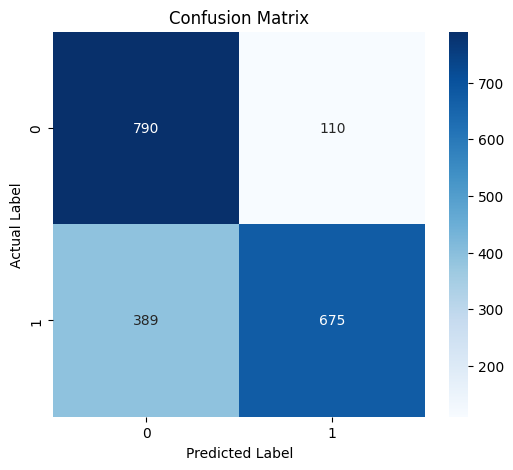

In [17]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Evaluate and Visualize results
def plot_performance(history):
    # Retrieve predictions and true labels for the validation set
    y_true = []
    y_pred = []
    
    for images, labels in val_ds:
        preds = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        # Since it's sigmoid, values > 0.5 are class 1, else class 0
        y_pred.extend((preds > 0.5).astype("int32"))

    # Generate Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_performance(history)

In [14]:
model.save('tb_bm_model.keras')

In [15]:
model.evaluate(test_ds)

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.7451 - loss: 0.7220


[0.7220491766929626, 0.7450980544090271]